# Q´aq´ Lab
## Exploratory Analysis of BASS-II SIBAL Experimental Data

**Objective:** Examine the available PSI/BASS-II experimental data to understand its structure, quality, experimental coverage, and documented outcomes before deciding how it can support the prototype.


## 1. Setup
### 1.1 Libraries and visualization tools



In [ ]:
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
import sklearn as sk
import csv
import os
import xgboost as xgb

## 2. Data loading and first look
### 2.1 Load the English BASS-II SIBAL dataset




In [ ]:
import pandas as pd

df = pd.read_csv("bassii_sibal_tests_EN.csv")
df.head()

,test_id,investigation,material,composition,geometry,thickness_mm,area_density_mg_cm2,sample_width_cm,exposed_length_cm,gravity,...,oxygen_caveat,reused_sample,observed_outcome,ignited_explicit,sustained_spread_label,model_eligible,exclusion_reason,source_page,source_table,original_comment
0,GMT45-T1,BASS-II,SIBAL fabric,75% cotton / 25% fiberglass,Flat fabric sheet,0.32,18.2,2.2,10,Microgravity (ISS),...,Yes,No,Outcome not specified,Not determined,NaN,False,The table does not report the sustained flame ...,95,Table 7.1,-----------------------------
1,GMT45-T2,BASS-II,SIBAL fabric,75% cotton / 25% fiberglass,Flat fabric sheet,0.32,18.2,2.2,10,Microgravity (ISS),...,Yes,No,Outcome not specified,Not determined,NaN,False,The table does not report the sustained flame ...,95,Table 7.1,-----------------------------
2,GMT45-T4,BASS-II,SIBAL fabric,75% cotton / 25% fiberglass,Flat fabric sheet,0.32,18.2,2.2,10,Microgravity (ISS),...,No,No,Flame extinction by quenching,Yes,NaN,False,The flame extinguishes after the flow is chang...,95,Table 7.1,Quenched
3,GMT45-T15,BASS-II,SIBAL fabric,75% cotton / 25% fiberglass,Flat fabric sheet,0.32,18.2,2.2,10,Microgravity (ISS),...,No,No,No blowoff,Yes,NaN,False,The observed event does not unambiguously esta...,95,Table 7.1,No blowoff
4,GMT100-T5,BASS-II,SIBAL fabric,75% cotton / 25% fiberglass,Flat fabric sheet,0.32,18.2,2.2,10,Microgravity (ISS),...,No,No,Outcome not specified,Not determined,NaN,False,The table does not report the sustained flame ...,95,Table 7.1,-----------------------------


## 3. Initial data audit

This section establishes the size, structure, completeness, and variability of the dataset before interpreting the experimental results


### 3.1 Dataset dimensions




In [ ]:
print("Rows and Columns:", df.shape)

Rows and Columns: (27, 26)


### 3.2 Column structure and data types



In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27 entries, 0 to 26
Data columns (total 26 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   test_id                 27 non-null     object 
 1   investigation           27 non-null     object 
 2   material                27 non-null     object 
 3   composition             27 non-null     object 
 4   geometry                27 non-null     object 
 5   thickness_mm            27 non-null     float64
 6   area_density_mg_cm2     27 non-null     float64
 7   sample_width_cm         27 non-null     float64
 8   exposed_length_cm       27 non-null     int64  
 9   gravity                 27 non-null     object 
 10  pressure_atm            27 non-null     int64  
 11  flow_direction          27 non-null     object 
 12  airflow_start_cm_s      27 non-null     float64
 13  airflow_end_cm_s        27 non-null     float64
 14  airflow_profile         27 non-null     obje

### 3.3 Missing values


In [ ]:
df.isna().sum().sort_values(ascending=False)

,0
sustained_spread_label,27
test_id,0
material,0
composition,0
geometry,0
thickness_mm,0
area_density_mg_cm2,0
sample_width_cm,0
exposed_length_cm,0
investigation,0


### 3.4 Unique values and variable variation



In [ ]:
df.nunique().sort_values()

,0
sustained_spread_label,0
investigation,1
composition,1
material,1
area_density_mg_cm2,1
thickness_mm,1
gravity,1
geometry,1
pressure_atm,1
flow_direction,1


## 4. Derived fields and summary metrics
### 4.1 Prepare analysis fields and summarize available evidence



In [ ]:
analysis_df = df.copy()

analysis_df["airflow_change_cm_s"] = (
    analysis_df["airflow_end_cm_s"]
    - analysis_df["airflow_start_cm_s"]
)

analysis_df["session_id"] = (
    analysis_df["test_id"]
    .str.extract(r"^(GMT\d+)")
)

known_ignition = analysis_df["ignited_explicit"].isin(
    ["Sí", "No"]
)

metrics = pd.DataFrame({
    "Metric": [
        "Tests",
        "Sessions GMT",
        "Duplicated IDs",
        "Ignition state",
        "Confirmed Ignitions",
        "No Ignition",
        "Undetermined Ignition",
        "Reused Samples",
        "Propagations labels available",
        "Elegible tests for Models"
    ],
    "Value": [
        len(analysis_df),
        analysis_df["session_id"].nunique(),
        analysis_df["test_id"].duplicated().sum(),
        known_ignition.sum(),
        (analysis_df["ignited_explicit"] == "Yes").sum(),
        (analysis_df["ignited_explicit"] == "No").sum(),
        (analysis_df["ignited_explicit"] == "Non determined").sum(),
        (analysis_df["reused_sample"] == "Yes").sum(),
        analysis_df["sustained_spread_label"].notna().sum(),
        analysis_df["model_eligible"].sum()
    ]
})

metrics

,Metric,Value
0,Tests,27
1,Sessions GMT,6
2,Duplicated IDs,0
3,Ignition state,6
4,Confirmed Ignitions,14
5,No Ignition,6
6,Undetermined Ignition,0
7,Reused Samples,8
8,Propagations labels available,0
9,Elegible tests for Models,0


## 5. Visual exploration



### 5.1 Documented outcomes by sample condition



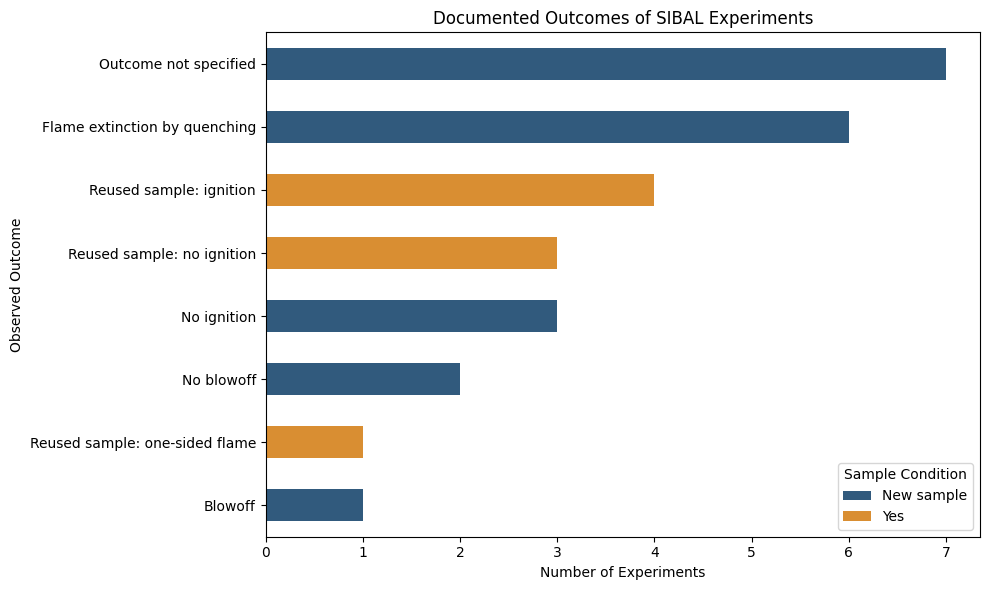

In [ ]:
outcome_table = pd.crosstab(
    analysis_df["observed_outcome"],
    analysis_df["reused_sample"]
).rename(columns={
    "No": "New sample",
    "Sí": "Reused sample"
})

outcome_table = outcome_table.loc[
    outcome_table.sum(axis=1).sort_values().index
]

ax = outcome_table.plot(
    kind="barh",
    stacked=True,
    figsize=(10, 6),
    color=["#315A7D", "#D98E32"]
)

ax.set_title("Documented Outcomes of SIBAL Experiments")
ax.set_xlabel("Number of Experiments")
ax.set_ylabel("Observed Outcome")
ax.legend(title="Sample Condition")

plt.tight_layout()
plt.show()

From the graph, we can observe that the 27 SIBAL experiments present a variety of documented flame behaviors. The most frequent category is “Outcome not specified,” with 7 experiments (25.9%), followed by “Flame extinction by quenching,” with 6 experiments (22.2%).  Overall, the graph shows both a diversity of flame behaviors and a relevant amount of incomplete documentation.

### 5.2 Experimental conditions by ignition status and sample reuse


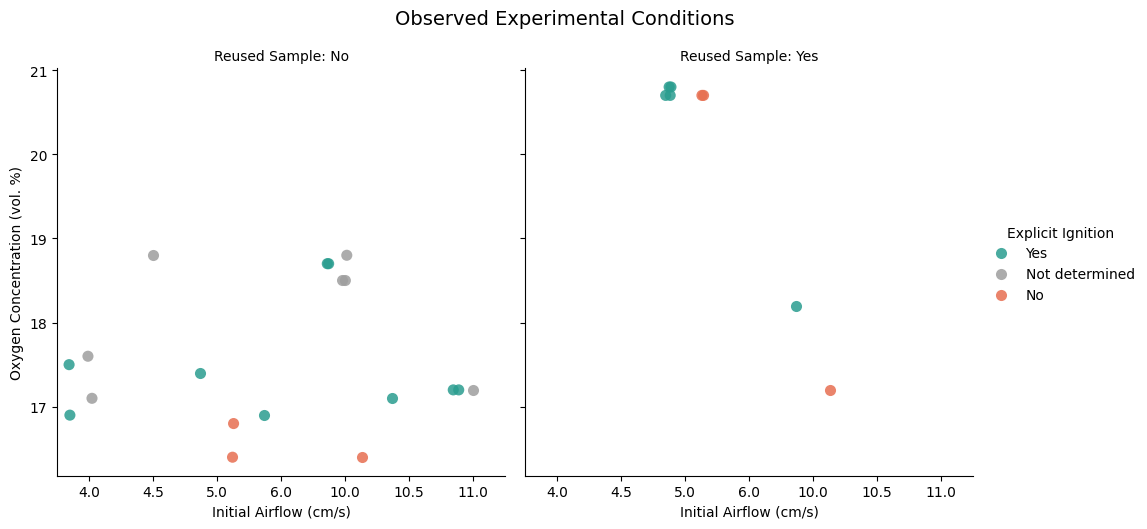

In [ ]:
palette = {
    "Yes": "#2A9D8F",
    "No": "#E76F51",
    "Not determined": "#9E9E9E"
}

g = sns.catplot(
    data=analysis_df,
    x="airflow_start_cm_s",
    y="oxygen_vol_pct",
    hue="ignited_explicit",
    col="reused_sample",
    kind="strip",
    dodge=True,
    jitter=0.15,
    size=8,
    alpha=0.85,
    palette=palette,
    height=5,
    aspect=1
)

g.set_axis_labels(
    "Initial Airflow (cm/s)",
    "Oxygen Concentration (vol. %)"
)

g.set_titles("Reused Sample: {col_name}")
g._legend.set_title("Explicit Ignition")

g.figure.suptitle(
    "Observed Experimental Conditions",
    y=1.05,
    fontsize=14
)

plt.show()

The figure shows that new samples were tested across a broader range of experimental conditions, with oxygen concentrations of approximately 16.4% to 18.8% and initial airflow values between approximately 3.8 and 11 cm/s. In contrast, reused samples were represented by fewer experiments concentrated around specific combinations of oxygen and airflow.

### 5.3 Initial versus final airflow



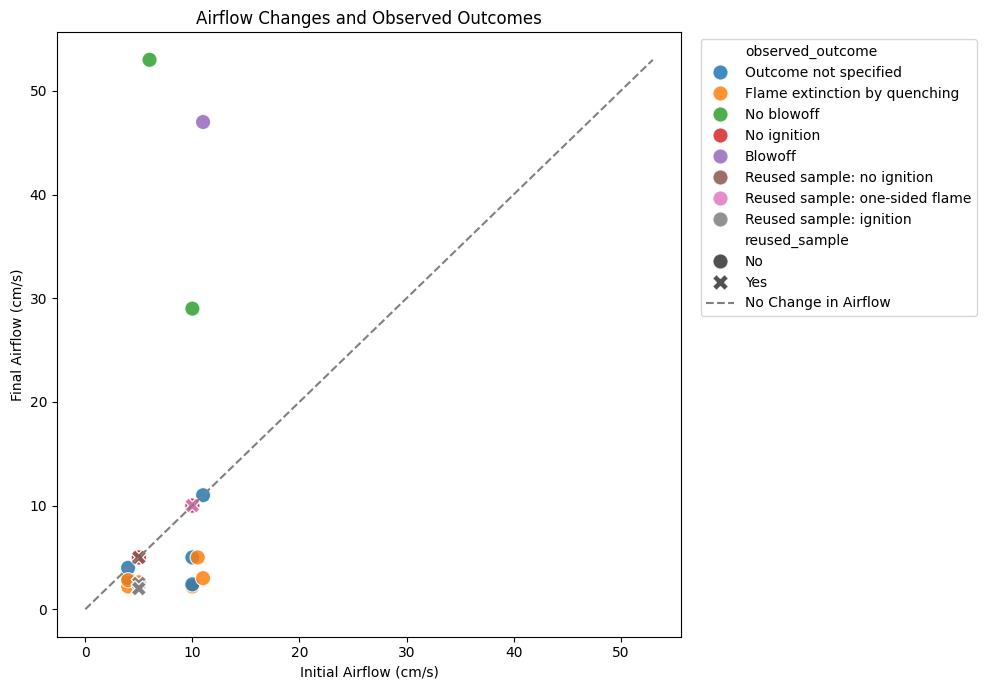

In [ ]:
plt.figure(figsize=(10, 7))

ax = sns.scatterplot(
    data=analysis_df,
    x="airflow_start_cm_s",
    y="airflow_end_cm_s",
    hue="observed_outcome",
    style="reused_sample",
    s=120,
    alpha=0.85
)

max_flow = analysis_df[
    ["airflow_start_cm_s", "airflow_end_cm_s"]
].to_numpy().max()

ax.plot(
    [0, max_flow],
    [0, max_flow],
    linestyle="--",
    color="gray",
    label="No Change in Airflow"
)

plt.title("Airflow Changes and Observed Outcomes")
plt.xlabel("Initial Airflow (cm/s)")
plt.ylabel("Final Airflow (cm/s)")
plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

The figure compares the initial and final airflow of each experiment, while the dashed diagonal line represents conditions in which airflow did not change. Most observations are concentrated between approximately 4 and 11 cm/s of initial airflow and 2 and 11 cm/s of final airflow. Points below the reference line indicate a reduction in airflow, whereas points near the line indicate little or no change.

### 5.4 Experimental coverage: oxygen and initial airflow




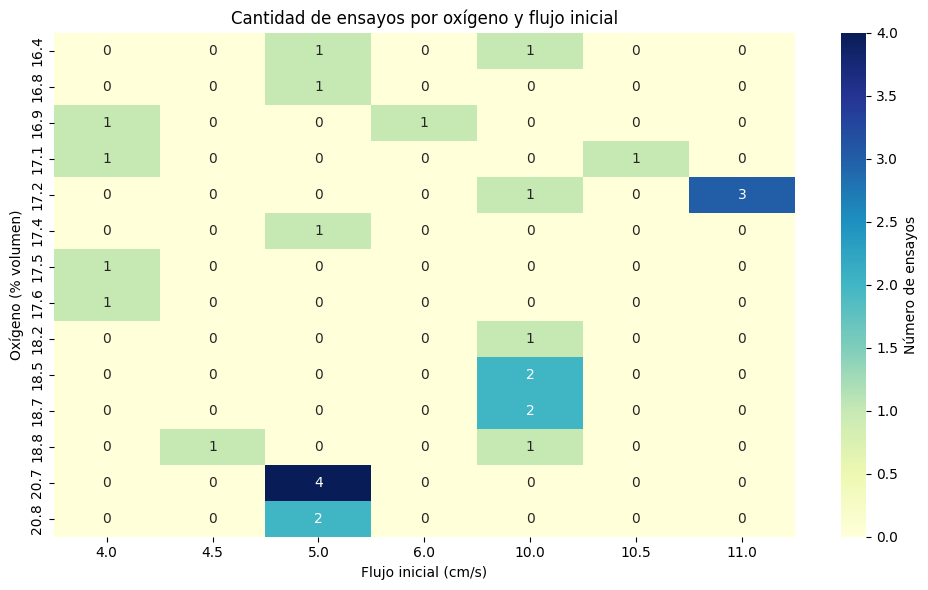

In [ ]:
coverage = pd.crosstab(
    analysis_df["oxygen_vol_pct"],
    analysis_df["airflow_start_cm_s"]
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    coverage,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    cbar_kws={"label": "Número de ensayos"}
)

plt.title("Cantidad de ensayos por oxígeno y flujo inicial")
plt.xlabel("Flujo inicial (cm/s)")
plt.ylabel("Oxígeno (% volumen)")

plt.tight_layout()
plt.show()

## 6. Evidence-based interpretation
### 6.1 Main observations

Write three to five findings that are directly supported by a table or figure above.

- **Observation 1:**
- **Observation 2:**
- **Observation 3:**

### 6.2 Questions raised by the data

- **Question 1:**
- **Question 2:**


## 7. Limitations and uncertainty

Document the limits of the available PSI/BASS-II subset before making claims.

- **Missing or undetermined information:**
- **Experimental coverage limitations:**
- **Possible effect of reused samples:**
- **Variables or evidence still needed:**
- **Claims this dataset does not support:**


## 8. Implications for the Ember prototype

Translate the analysis into product decisions without overstating the evidence.

### 8.1 Information the prototype can show
-

### 8.2 Search or filter fields supported by the data
-

### 8.3 Warnings or context the user should see
-

### 8.4 Information that should be verified in the original report
-


## 9. Final conclusions

Summarize your work in a concise format:

- **Three evidence-backed findings:**
- **Two important limitations:**
- **One prototype decision informed by the analysis:**
